# 🛡️ ToxicGuardAI — Training & Evaluation Notebook
### Explainable multilingual toxic comment detection with BERT + XAI + GenAI (English · हिन्दी · Hinglish)

**Runtime:** `Runtime → Change runtime type → T4 GPU`. Full run ≈ 35–45 min.

| Rubric criterion | CO | Marks | Notebook section |
|---|---|---|---|
| Text extraction, preprocessing, cleaning & vectorisation of unstructured data | CO1 | 7 | §1 – §3 |
| Implementation & evaluation of sentiment analysis and information extraction | CO2 | 8 | §4 – §7 |
| Topic modelling / multilingual NLP with NLP techniques & cloud AI services | CO3 | 7 | §8 – §9 |
| Generative AI / LLM application, prompt engineering & integration | CO4 | 8 | §10 – §11 |

**Outputs (copied into the Streamlit repo):** fine-tuned model on the Hugging Face Hub + `artifacts/` → `metrics.json`, `thresholds.json`, `tfidf.joblib`, `topic_model.joblib`.

**Colab secrets (🔑 icon in the left bar):** `HF_TOKEN` (write access, required to push the model) and `ANTHROPIC_API_KEY` (optional, for §10).

## 0 · Setup

In [1]:
!pip install -q "transformers>=4.46" "datasets>=2.20" "accelerate>=0.33" scikit-learn==1.9.1 joblib \
               vaderSentiment deep-translator langdetect "anthropic>=0.75" huggingface_hub

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, re, json, html, time, random, unicodedata, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch, joblib
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score, accuracy_score,
                             confusion_matrix, classification_report, roc_curve)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

def get_secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

HF_TOKEN = get_secret("HF_TOKEN")
ANTHROPIC_API_KEY = get_secret("ANTHROPIC_API_KEY")
print("HF token:", bool(HF_TOKEN), "| Anthropic key:", bool(ANTHROPIC_API_KEY))

Device: cuda Tesla T4
HF token: True | Anthropic key: False


In [25]:
# ---------------- configuration ----------------
MODEL_NAME   = "google-bert/bert-base-multilingual-cased"   # multilingual BERT (104 languages incl. Hindi)
HF_REPO      = "Vivek1717/toxicguard-mbert"            # <-- change to your Hugging Face username
LABELS       = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
MAX_LEN      = 128
EPOCHS       = 2
BATCH        = 32
LR           = 2e-5
JIGSAW_CLEAN_SAMPLE = 30000      # clean Jigsaw comments kept (all toxic ones are kept)
MULTI_UPSAMPLE      = 2          # repeat Hindi/Hinglish training rows to balance languages
OUT_DIR, ART_DIR = "toxicguard-mbert", "artifacts"
os.makedirs(ART_DIR, exist_ok=True)
METRICS = {"training": {"base_model": MODEL_NAME, "max_len": MAX_LEN, "epochs": EPOCHS, "batch_size": BATCH,
                        "learning_rate": LR, "loss": "masked BCE with pos_weight", "seed": SEED}}

## 1 · Text extraction — loading unstructured comment corpora  `CO1`
* **Jigsaw Toxic Comment Classification** – 160k English Wikipedia talk-page comments, 6 toxicity labels.
* **TextDetox Multilingual Toxicity** – binary toxic labels; we use the `en`, `hi` (Hindi, Devanagari) and `hin` (Hinglish, romanised) splits.

TextDetox rows only carry the `toxic` label → the other 5 labels are set to **-1 (unknown)** and masked out of the loss.

In [4]:
from datasets import load_dataset

jig = load_dataset("thesofakillers/jigsaw-toxic-comment-classification-challenge", split="train").to_pandas()
jig = jig.rename(columns={"comment_text": "text"})
jig["any"] = jig[LABELS].max(axis=1)
jig = pd.concat([jig[jig["any"] == 1], jig[jig["any"] == 0].sample(JIGSAW_CLEAN_SAMPLE, random_state=SEED)])
jig["lang"], jig["source"] = "en", "jigsaw"
jig = jig[["text", "lang", "source"] + LABELS]

frames = [jig]
for split, lang in [("en", "en"), ("hi", "hi"), ("hin", "hinglish")]:
    d = load_dataset("textdetox/multilingual_toxicity_dataset", split=split).to_pandas()
    for lab in LABELS[1:]:
        d[lab] = -1
    d["lang"], d["source"] = lang, "textdetox"
    frames.append(d[["text", "lang", "source"] + LABELS])

raw = pd.concat(frames, ignore_index=True)
print(raw.shape)
raw.groupby(["source", "lang"]).agg(n=("text", "size"), toxic_rate=("toxic", "mean")).round(3)

README.md:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 68.8MB            

train.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B / 60.4MB            

test.csv: downloading bytes:           |  0.00B            

test_labels.csv:   0%|          | 0.00/4.98M [00:00<?, ?B/s]

... (46 outputs left out)

Generating tt split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating ja split:   0%|          | 0/5000 [00:00<?, ? examples/s]

(60588, 9)


n  toxic_rate
source    lang                       
jigsaw    en        46225       0.331
textdetox en         5000       0.500
          hi         5000       0.500
          hinglish   4363       0.504

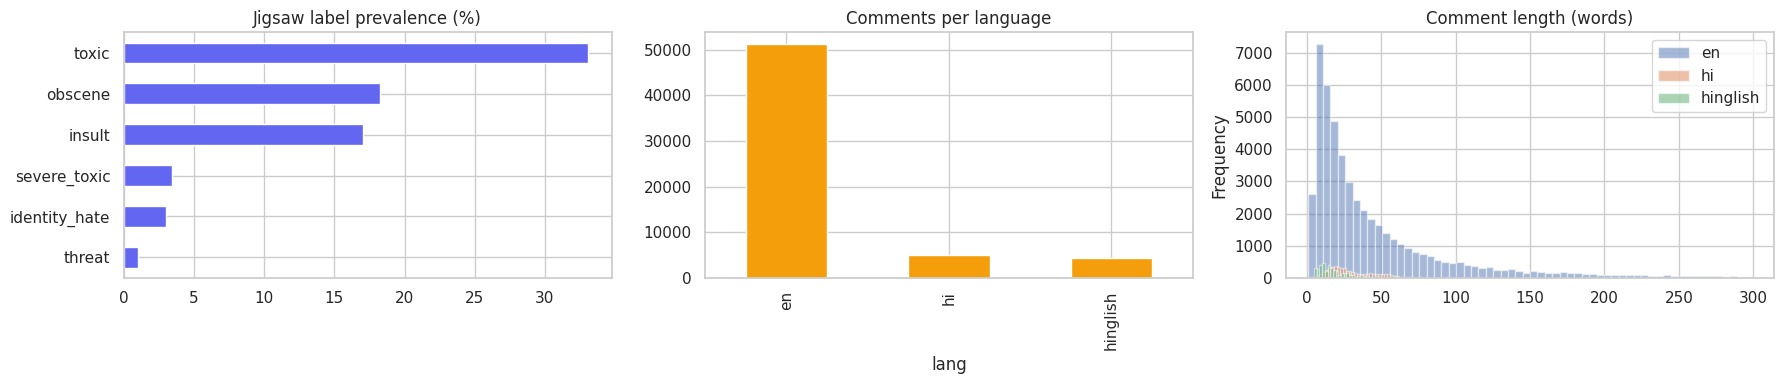

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
(jig[LABELS].mean() * 100).sort_values().plot.barh(ax=ax[0], color="#6366F1"); ax[0].set_title("Jigsaw label prevalence (%)")
raw["lang"].value_counts().plot.bar(ax=ax[1], color="#F59E0B"); ax[1].set_title("Comments per language")
raw.assign(words=raw.text.str.split().str.len()).query("words < 300").groupby("lang")["words"].plot.hist(
    ax=ax[2], bins=60, alpha=.5, legend=True); ax[2].set_title("Comment length (words)")
plt.tight_layout(); plt.show()

## 2 · Preprocessing & cleaning  `CO1`
Two views of every comment are produced (identical to `src/preprocessing.py` in the app):

| View | Used by | Operations |
|---|---|---|
| `model_text` (light) | BERT | HTML unescape/tag strip · Unicode NFC · URL/e-mail removal · `@user` masking · `#hashtag` split · elongation squashing (`stupiddddd→stupidd`) · repeated punctuation |
| `norm_text` (aggressive) | TF-IDF, LDA | + lower-casing · Devanagari-aware tokenisation · Hinglish spelling normalisation · EN+HI stop-word removal |

In [6]:
URL_RE = re.compile(r"(https?://\S+|www\.\S+)", re.I); EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
MENTION_RE = re.compile(r"(?<!\w)@\w+"); HASHTAG_RE = re.compile(r"(?<!\w)#(\w+)"); HTML_TAG_RE = re.compile(r"<[^>]+>")
ELONG_RE = re.compile(r"(\w)\1{2,}"); PUNCT_RE = re.compile(r"([!?.,])\1+"); WS_RE = re.compile(r"\s+")
TOKEN_RE = re.compile(r"[ऀ-ॿ]+|[A-Za-z0-9']+")
HINGLISH_NORM = {"nhi": "nahi", "nai": "nahi", "nahin": "nahi", "kyu": "kyun", "kyon": "kyun", "hy": "hai", "bhot": "bahut",
                 "bohot": "bahut", "bht": "bahut", "kr": "kar", "krna": "karna", "kro": "karo", "yr": "yaar", "yar": "yaar",
                 "mai": "main", "acha": "accha", "thik": "theek", "pls": "please", "plz": "please", "tm": "tum", "hu": "hoon"}
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
STOP_HI = set('''का की के को में से है हैं था थी थे और या पर भी तो ही यह वह ये वो इस उस एक कि जो कर करना किया गया हो होता होती रहा रही रहे
नहीं ना लिए साथ तक अब जब तब कुछ सब हम आप मैं मुझे मेरा hai hain ho tha thi the aur ya par bhi to hi yeh ye woh wo is us ek ki ka ke ko
mein me se kar karna kiya gaya hota hoti raha rahi rahe nahi na liye sath tak ab jab tab kuch sab hum main mujhe mera meri mere'''.split())
STOP = set(ENGLISH_STOP_WORDS) | STOP_HI

def clean_for_model(t):
    t = html.unescape(str(t)); t = unicodedata.normalize("NFC", t); t = HTML_TAG_RE.sub(" ", t)
    t = URL_RE.sub(" ", t); t = EMAIL_RE.sub(" ", t); t = MENTION_RE.sub("@user", t); t = HASHTAG_RE.sub(r"\1", t)
    t = ELONG_RE.sub(r"\1\1", t); t = PUNCT_RE.sub(r"\1", t)
    return WS_RE.sub(" ", t).strip()

def normalize(t, lang="en"):
    toks = TOKEN_RE.findall(clean_for_model(t).lower())
    if lang == "hinglish":
        toks = [HINGLISH_NORM.get(x, x) for x in toks]
    return " ".join(x for x in toks if x not in STOP and len(x) > 1 and not x.isdigit())

df = raw.copy()
df["model_text"] = df.text.map(clean_for_model)
df["norm_text"] = [normalize(t, l) for t, l in zip(df.text, df.lang)]
before = len(df)
df = df[df.model_text.str.len() > 2].drop_duplicates("model_text").reset_index(drop=True)
print(f"Removed {before - len(df)} empty/duplicate rows -> {len(df)} comments")
pd.set_option("display.max_colwidth", 90)
df.groupby("lang").sample(2, random_state=1)[["lang", "text", "model_text", "norm_text"]]

Removed 316 empty/duplicate rows -> 60272 comments


,lang,text,model_text,norm_text
11864,en,n b nb \n\nfuck you duchas nachui,n b nb fuck you duchas nachui,nb fuck duchas nachui
50200,en,He’s a clown and we’re just gonna go ahead and name him “BOO BOO THE F’N FOOL”.,He’s a clown and we’re just gonna go ahead and name him “BOO BOO THE F’N FOOL”.,clown just gonna ahead boo boo fool
51622,hi,"देश के किसानों,गरीबों,मजदुरों व मध्यम वर्ग के सभी साथी मिलकर इस कुत्ती,कमीनी,गंदी,जुमल...","देश के किसानों,गरीबों,मजदुरों व मध्यम वर्ग के सभी साथी मिलकर इस कुत्ती,कमीनी,गंदी,जुमल...",देश किसानों गरीबों मजदुरों मध्यम वर्ग सभी साथी मिलकर कुत्ती कमीनी गंदी जुमली सरकार खिल...
55181,hi,"फेक न्यूज के अन्तर्गत अब तक 2,458 मामलों को संज्ञान में लेते हुए कार्यवाही की गई है। अ...","फेक न्यूज के अन्तर्गत अब तक 2,458 मामलों को संज्ञान में लेते हुए कार्यवाही की गई है। अ...",फेक न्यूज अन्तर्गत मामलों संज्ञान लेते हुए कार्यवाही गई है। प्रदेश एफआईआर दर्ज करते हु...
58803,hinglish,Aray lalu wa ... ka .. satta ma rahkar chara ghotala keya jaaa sakta hai ka ..... Aur...,Aray lalu wa . ka . satta ma rahkar chara ghotala keya jaa sakta hai ka . Aur Satta ma...,aray lalu wa satta ma rahkar chara ghotala keya jaa sakta satta ma rahkar mitti khakar...
60242,hinglish,Yaarr har baat pe armmy ka compare mt kro... woh apni jagah best hai hatsss off hai un...,Yaarr har baat pe armmy ka compare mt kro. woh apni jagah best hai hatss off hai unhe....,yaarr har baat pe armmy compare mt karo apni jagah best hatss unhe inhone jo karke dik...


In [7]:
from sklearn.model_selection import train_test_split
df["strat"] = df["lang"] + "_" + df["toxic"].astype(str)
train_df, test_df = train_test_split(df, test_size=0.15, stratify=df.strat, random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.10, stratify=train_df.strat, random_state=SEED)
print({k: len(v) for k, v in [("train", train_df), ("val", val_df), ("test", test_df)]})
test_df.groupby("lang").size()

{'train': 46107, 'val': 5124, 'test': 9041}


,0
lang,
en,7661
hi,745
hinglish,635


## 3 · Vectorisation  `CO1`
* **Sparse:** TF-IDF on word uni+bi-grams → classical baseline (one Logistic Regression per label, trained only on rows where that label is known).
* **Dense:** BERT WordPiece tokenisation → contextual embeddings (fine-tuned in §4).

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, max_features=50000, sublinear_tf=True,
                        token_pattern=r"(?u)[ऀ-ॿ]+|\b\w\w+\b")
Xtr = tfidf.fit_transform(train_df.norm_text); Xte = tfidf.transform(test_df.norm_text)
print("TF-IDF matrix:", Xtr.shape, f"| sparsity {1 - Xtr.nnz / np.prod(Xtr.shape):.4%}")

base_probs = np.full((len(test_df), len(LABELS)), np.nan)
for j, lab in enumerate(LABELS):
    m = train_df[lab].values >= 0
    clf_lr = LogisticRegression(max_iter=2000, C=4, class_weight="balanced").fit(Xtr[m], train_df[lab].values[m])
    base_probs[:, j] = clf_lr.predict_proba(Xte)[:, 1]
joblib.dump(tfidf, f"{ART_DIR}/tfidf.joblib")

# Top TF-IDF features for the toxic class
lr_tox = LogisticRegression(max_iter=2000, C=4, class_weight="balanced").fit(Xtr, train_df.toxic.values)
feats = tfidf.get_feature_names_out(); top = np.argsort(-lr_tox.coef_[0])[:25]
print("Most toxic n-grams:", ", ".join(feats[top]))

TF-IDF matrix: (46107, 50000) | sparsity 99.9535%
Most toxic n-grams: fuck, fucking, stupid, shit, idiot, ass, bullshit, bitch, suck, asshole, hell, dick, crap, faggot, penis, sucks, pathetic, cunt, rt, idiots, moron, dumb, shut, cock, nigger


In [9]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
for s in ["You are a pathetic idiot", "तू पागल है क्या", "Tu pagal hai kya bewakoof"]:
    print(f"{s:30s} -> {tokenizer.tokenize(s)}")
lens = [len(x) for x in tokenizer(train_df.model_text.sample(3000, random_state=1).tolist())["input_ids"]]
print(f"WordPiece length: median {np.median(lens):.0f}, 95th pct {np.percentile(lens, 95):.0f} -> MAX_LEN={MAX_LEN}")

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

You are a pathetic idiot       -> ['You', 'are', 'a', 'path', '##eti', '##c', 'idi', '##ot']
तू पागल है क्या                -> ['त', '##ू', 'प', '##ाग', '##ल', 'है', 'क', '##्या']
Tu pagal hai kya bewakoof      -> ['Tu', 'pagal', 'hai', 'ky', '##a', 'be', '##wak', '##oof']


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (666 > 512). Running this sequence through the model will result in indexing errors


WordPiece length: median 44, 95th pct 256 -> MAX_LEN=128


## 4 · Fine-tuning multilingual BERT (multi-label)  `CO2`
* 6 sigmoid outputs, **masked BCE loss**: unknown labels (-1) contribute 0 loss, so binary-only Hindi/Hinglish data trains the `toxic` head while sub-category heads learn from Jigsaw and transfer cross-lingually.
* `pos_weight` counters label imbalance (threat / identity_hate are rare).
* Hindi/Hinglish rows are up-sampled ×2 to balance languages.

In [11]:
from torch.utils.data import Dataset
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding

class CommentDS(Dataset):
    def __init__(self, frame):
        self.enc = tokenizer(frame.model_text.tolist(), truncation=True, max_length=MAX_LEN)
        self.y = frame[LABELS].values.astype(np.float32)
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}; item["labels"] = self.y[i].tolist(); return item

train_bal = pd.concat([train_df] + [train_df[train_df.lang.isin(["hi", "hinglish"])]] * (MULTI_UPSAMPLE - 1))
train_ds, val_ds, test_ds = CommentDS(train_bal), CommentDS(val_df), CommentDS(test_df)

yk = train_bal[LABELS].values
pos = np.array([(yk[:, j] == 1).sum() for j in range(6)]); neg = np.array([(yk[:, j] == 0).sum() for j in range(6)])
POS_WEIGHT = torch.tensor(np.clip(neg / np.maximum(pos, 1), 1, 10), dtype=torch.float32)
print("pos_weight:", dict(zip(LABELS, POS_WEIGHT.numpy().round(2))))

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), problem_type="multi_label_classification",
    id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)})

class MaskedBCETrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        mask = (labels >= 0).float()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(
            logits, labels.clamp(min=0), pos_weight=POS_WEIGHT.to(logits.device), reduction="none")
        loss = (loss * mask).sum() / mask.sum().clamp(min=1)
        return (loss, outputs) if return_outputs else loss

def masked_metrics(probs, y, thr=0.5):
    out = {}
    f1s, aucs = [], []
    for j, lab in enumerate(LABELS):
        m = y[:, j] >= 0
        yt, pp = y[m, j], probs[m, j]
        f1s.append(f1_score(yt, pp >= thr, zero_division=0))
        if len(np.unique(yt)) > 1: aucs.append(roc_auc_score(yt, pp))
    return {"macro_f1": float(np.mean(f1s)), "macro_auc": float(np.mean(aucs))}

def compute_metrics(p):
    probs = 1 / (1 + np.exp(-p.predictions)); return masked_metrics(probs, p.label_ids)

WARMUP_STEPS = int(0.06 * int(np.ceil(len(train_ds) / BATCH)) * EPOCHS)   # 6% warm-up (works on transformers v4 and v5)
args = TrainingArguments(
    output_dir="checkpoints", num_train_epochs=EPOCHS, learning_rate=LR, per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=64, warmup_steps=WARMUP_STEPS, weight_decay=0.01, fp16=(DEVICE == "cuda"),
    eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="macro_auc",
    save_total_limit=1, logging_steps=100, report_to="none", seed=SEED, dataloader_num_workers=2)

trainer = MaskedBCETrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                           data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics)
train_out = trainer.train()
METRICS["training"].update({"train_rows": len(train_bal), "val_rows": len(val_df), "test_rows": len(test_df),
                            "train_runtime_min": round(train_out.metrics["train_runtime"] / 60, 1)})

pos_weight: {'toxic': np.float32(1.58), 'severe_toxic': np.float32(10.0), 'obscene': np.float32(4.5), 'threat': np.float32(10.0), 'insult': np.float32(4.86), 'identity_hate': np.float32(10.0)}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.

Epoch,Training Loss,Validation Loss,Macro F1,Macro Auc
1,0.304027,0.286313,0.599227,0.968277
2,0.242249,0.272695,0.644924,0.970971


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

In [12]:
hist, losses = [], {}
for r in trainer.state.log_history:
    if "loss" in r: losses.setdefault(round(r["epoch"]), []).append(r["loss"])
    if "eval_macro_f1" in r:
        hist.append({"epoch": round(r["epoch"]), "val_macro_f1": r["eval_macro_f1"], "val_macro_auc": r["eval_macro_auc"],
                     "val_loss": r["eval_loss"]})
for h in hist: h["train_loss"] = float(np.mean(losses.get(h["epoch"], losses.get(h["epoch"] - 1, [np.nan]))))
METRICS["history"] = hist
pd.DataFrame(hist)

,epoch,val_macro_f1,val_macro_auc,val_loss,train_loss
0,1,0.599227,0.968277,0.286313,0.293582
1,2,0.644924,0.970971,0.272695,0.243792


## 5 · Threshold tuning (validation) & test-set evaluation  `CO2`

In [13]:
def predict(ds):
    p = trainer.predict(ds); return 1 / (1 + np.exp(-p.predictions)), p.label_ids

val_p, val_y = predict(val_ds)
THRESH = {}
for j, lab in enumerate(LABELS):
    m = val_y[:, j] >= 0
    grid = np.arange(0.05, 0.96, 0.01)
    THRESH[lab] = float(grid[np.argmax([f1_score(val_y[m, j], val_p[m, j] >= t, zero_division=0) for t in grid])])
print("Tuned thresholds:", THRESH)

test_p, test_y = predict(test_ds)
per_label, f1s, aucs, all_t, all_p = {}, [], [], [], []
for j, lab in enumerate(LABELS):
    m = test_y[:, j] >= 0; yt, pp = test_y[m, j].astype(int), test_p[m, j]; pr = (pp >= THRESH[lab]).astype(int)
    per_label[lab] = {"precision": precision_score(yt, pr, zero_division=0), "recall": recall_score(yt, pr, zero_division=0),
                      "f1": f1_score(yt, pr, zero_division=0), "roc_auc": roc_auc_score(yt, pp), "support": int(yt.sum()),
                      "threshold": THRESH[lab]}
    all_t.append(yt); all_p.append(pr)
per_label = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in per_label.items()}
yt_b, pr_b = test_y[:, 0].astype(int), (test_p[:, 0] >= THRESH["toxic"]).astype(int)
METRICS["per_label"] = per_label
METRICS["overall"] = {
    "macro_f1": float(np.mean([v["f1"] for v in per_label.values()])),
    "micro_f1": float(f1_score(np.concatenate(all_t), np.concatenate(all_p))),
    "macro_auc": float(np.mean([v["roc_auc"] for v in per_label.values()])),
    "binary_accuracy": float(accuracy_score(yt_b, pr_b)), "binary_f1": float(f1_score(yt_b, pr_b))}
METRICS["confusion_matrix"] = confusion_matrix(yt_b, pr_b).tolist()
print(json.dumps(METRICS["overall"], indent=2))
print(classification_report(yt_b, pr_b, target_names=["non-toxic", "toxic"]))
pd.DataFrame(per_label).T.round(3)

Tuned thresholds: {'toxic': 0.6000000000000002, 'severe_toxic': 0.8400000000000002, 'obscene': 0.8100000000000002, 'threat': 0.6100000000000001, 'insult': 0.8000000000000002, 'identity_hate': 0.9100000000000003}


{
  "macro_f1": 0.6928454339790714,
  "micro_f1": 0.8262953663547136,
  "macro_auc": 0.9651031392565002,
  "binary_accuracy": 0.9076429598495742,
  "binary_f1": 0.8786160779183021
}
              precision    recall  f1-score   support

   non-toxic       0.94      0.91      0.93      5695
       toxic       0.86      0.90      0.88      3346

    accuracy                           0.91      9041
   macro avg       0.90      0.91      0.90      9041
weighted avg       0.91      0.91      0.91      9041



,precision,recall,f1,roc_auc,support,threshold
toxic,0.855,0.903,0.879,0.971,3346.0,0.60
severe_toxic,0.480,0.684,0.564,0.975,250.0,0.84
obscene,0.829,0.887,0.857,0.980,1255.0,0.81
threat,0.468,0.537,0.500,0.938,67.0,0.61
insult,0.714,0.839,0.771,0.963,1158.0,0.80
identity_hate,0.641,0.540,0.586,0.964,215.0,0.91


,n,accuracy,f1,roc_auc
en,7661.0,0.919,0.886,0.977
hi,745.0,0.942,0.940,0.988
hinglish,635.0,0.728,0.757,0.803


TF-IDF+LR macro F1 0.640 / AUC 0.956  vs  mBERT macro F1 0.693 / AUC 0.965


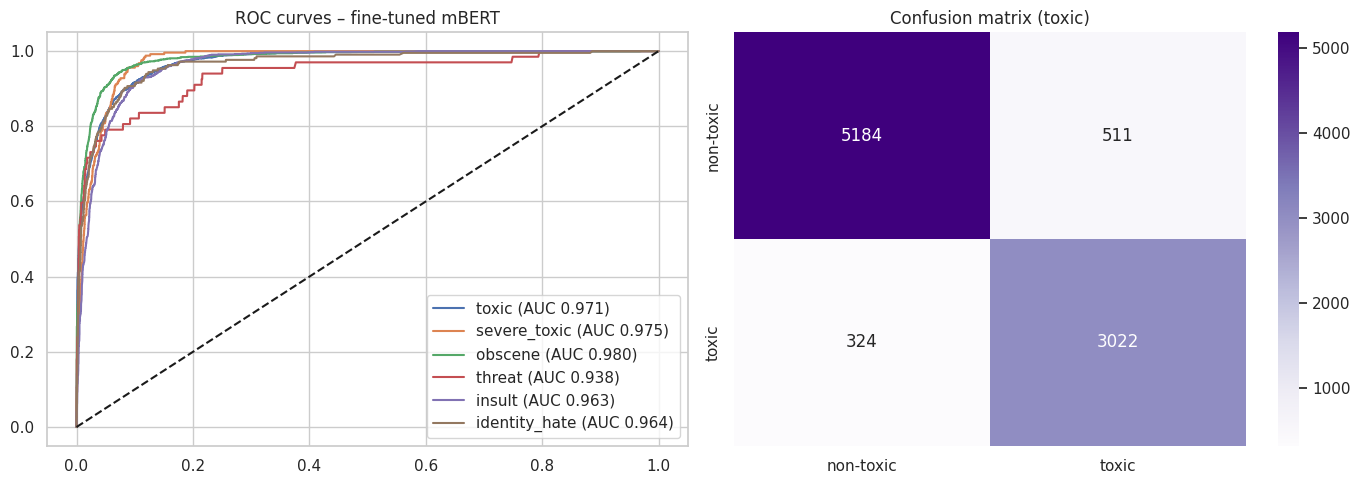

In [14]:
# Per-language evaluation (binary toxic head) + classical baseline comparison
per_lang = {}
for lang in ["en", "hi", "hinglish"]:
    m = (test_df.lang == lang).values
    per_lang[lang] = {"n": int(m.sum()), "accuracy": float(accuracy_score(yt_b[m], pr_b[m])),
                      "f1": float(f1_score(yt_b[m], pr_b[m])), "roc_auc": float(roc_auc_score(yt_b[m], test_p[m, 0]))}
METRICS["per_language"] = per_lang

bl = {}
for j, lab in enumerate(LABELS):
    m = test_y[:, j] >= 0; yt = test_y[m, j].astype(int)
    bl[lab] = {"f1": float(f1_score(yt, base_probs[m, j] >= 0.5)), "roc_auc": float(roc_auc_score(yt, base_probs[m, j]))}
METRICS["baseline_tfidf"] = {"per_label": bl, "macro_f1": float(np.mean([v["f1"] for v in bl.values()])),
                             "macro_auc": float(np.mean([v["roc_auc"] for v in bl.values()]))}
display(pd.DataFrame(per_lang).T.round(3))
print("TF-IDF+LR macro F1 %.3f / AUC %.3f  vs  mBERT macro F1 %.3f / AUC %.3f" % (
    METRICS["baseline_tfidf"]["macro_f1"], METRICS["baseline_tfidf"]["macro_auc"],
    METRICS["overall"]["macro_f1"], METRICS["overall"]["macro_auc"]))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for j, lab in enumerate(LABELS):
    m = test_y[:, j] >= 0; fpr, tpr, _ = roc_curve(test_y[m, j], test_p[m, j])
    ax[0].plot(fpr, tpr, label=f"{lab} (AUC {per_label[lab]['roc_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curves – fine-tuned mBERT"); ax[0].legend()
sns.heatmap(METRICS["confusion_matrix"], annot=True, fmt="d", cmap="Purples", ax=ax[1],
            xticklabels=["non-toxic", "toxic"], yticklabels=["non-toxic", "toxic"]); ax[1].set_title("Confusion matrix (toxic)")
plt.tight_layout(); plt.show()

## 6 · Sentiment analysis — implementation & evaluation  `CO2`
**VADER** (Valence Aware Dictionary and sEntiment Reasoner) – a rule-based lexicon model built for social-media text
(handles negation, intensifiers, CAPS and `!!!`). Evaluated on the **TweetEval sentiment** test set; then we study how
sentiment relates to toxicity on our test data.

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/validation-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  167kB            

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

{'dataset': 'TweetEval-sentiment (n=3000)', 'accuracy': 0.5226666666666666, 'macro_f1': 0.5219728071975542}
              precision    recall  f1-score   support

    negative       0.62      0.56      0.58       973
     neutral       0.66      0.43      0.52      1447
    positive       0.34      0.70      0.46       580

    accuracy                           0.52      3000
   macro avg       0.54      0.56      0.52      3000
weighted avg       0.59      0.52      0.53      3000



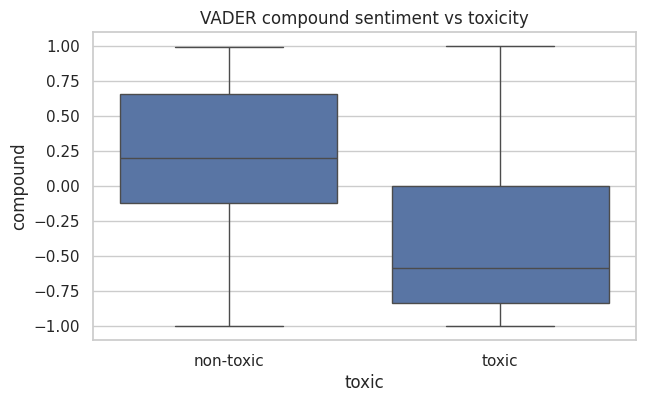

In [15]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
def vader_label(t):
    c = vader.polarity_scores(t)["compound"]; return 2 if c >= 0.05 else 0 if c <= -0.05 else 1

tw = load_dataset("cardiffnlp/tweet_eval", "sentiment", split="test").to_pandas().sample(3000, random_state=SEED)
tw["pred"] = tw.text.map(vader_label)
METRICS["sentiment_eval"] = {"dataset": "TweetEval-sentiment (n=3000)", "accuracy": float(accuracy_score(tw.label, tw.pred)),
                             "macro_f1": float(f1_score(tw.label, tw.pred, average="macro"))}
print(METRICS["sentiment_eval"])
print(classification_report(tw.label, tw.pred, target_names=["negative", "neutral", "positive"]))

en_test = test_df[test_df.lang == "en"].copy()
en_test["compound"] = en_test.model_text.map(lambda t: vader.polarity_scores(t)["compound"])
plt.figure(figsize=(7, 4)); sns.boxplot(data=en_test, x="toxic", y="compound")
plt.xticks([0, 1], ["non-toxic", "toxic"]); plt.title("VADER compound sentiment vs toxicity"); plt.show()

## 7 · Information extraction — implementation & evaluation  `CO2`
Who is the comment aimed at? We extract **identity-group mentions** (multilingual gazetteer), **direct targeting**
(2nd-person pronouns / @mentions) and structured artefacts (URLs, @mentions, #hashtags) with regular expressions,
and evaluate on a hand-labelled gold set. (The app adds spaCy NER on top.)

In [16]:
IDENTITY = {
  "religion": ["muslim", "muslims", "hindu", "hindus", "christian", "christians", "sikh", "jews", "jew", "islam", "मुसलमान", "हिंदू", "musalman"],
  "caste": ["dalit", "dalits", "brahmin", "brahmins", "caste", "दलित"],
  "gender": ["women", "woman", "girls", "girl", "aurat", "aurate", "ladki", "औरत", "महिला", "feminists"],
  "sexual_orientation": ["gay", "gays", "lesbian", "lgbt", "trans", "transgender", "hijra", "hijre"],
  "nationality_ethnicity": ["immigrants", "immigrant", "pakistani", "pakistanis", "biharis", "bihari", "chinese", "black", "blacks"],
}
SECOND = {"you", "your", "u", "ur", "yourself", "tu", "tum", "tera", "teri", "tere", "tujhe", "tumhara", "तू", "तुम", "तेरा", "तुझे"}
WORD = re.compile(r"[ऀ-ॿ]+|[A-Za-z']+")

def extract(t):
    w = {x.lower() for x in WORD.findall(t)}
    groups = {g for g, terms in IDENTITY.items() if w & set(terms)}
    target = "individual" if (w & SECOND or MENTION_RE.search(t)) else ("group" if groups else "none")
    return groups, target

GOLD = [  # (text, gold identity groups, gold target)
 ("You are such an idiot", set(), "individual"), ("All immigrants are criminals", {"nationality_ethnicity"}, "group"),
 ("Muslims should leave this country", {"religion"}, "group"), ("Tu pagal hai kya", set(), "individual"),
 ("Women can't drive, everyone knows it", {"gender"}, "group"), ("@rahul your post is garbage", set(), "individual"),
 ("Dalits ko yahan aane mat do", {"caste"}, "group"), ("Great match yesterday!", set(), "none"),
 ("गे लोग बीमार हैं", {"sexual_orientation"}, "group"), ("Hindus and Muslims are brothers", {"religion"}, "group"),
 ("तू बहुत घटिया इंसान है", set(), "individual"), ("Trans people deserve respect", {"sexual_orientation"}, "group"),
 ("Teri aukaat kya hai", set(), "individual"), ("Biharis are ruining the city", {"nationality_ethnicity"}, "group"),
 ("The weather is nice today", set(), "none"), ("Ladki ho to kitchen mein raho", {"gender"}, "group"),
 ("Gay marriage was legalised", {"sexual_orientation"}, "group"), ("Shut up you moron", set(), "individual"),
 ("Brahmins and dalits both protested", {"caste"}, "group"), ("Thanks for sharing this", set(), "none"),
]
tp = fp = fn = 0; tgt_ok = 0
for text, g_gold, t_gold in GOLD:
    g_pred, t_pred = extract(text)
    tp += len(g_pred & g_gold); fp += len(g_pred - g_gold); fn += len(g_gold - g_pred); tgt_ok += t_pred == t_gold
P, R = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
METRICS["ie_eval"] = {"precision": P, "recall": R, "f1": 2 * P * R / max(P + R, 1e-9), "target_accuracy": tgt_ok / len(GOLD), "n": len(GOLD)}
print(METRICS["ie_eval"])
# Error analysis: 'गे' (Devanagari transliteration of 'gay') is missed -> gazetteers need script variants.

{'precision': 1.0, 'recall': 0.9090909090909091, 'f1': 0.9523809523809523, 'target_accuracy': 0.95, 'n': 20}


## 8 · Topic modelling — LDA  `CO3`
Latent Dirichlet Allocation on the **toxic** English comments discovers *what* people are toxic about.
We select the number of topics by held-out perplexity, then cross-tabulate topics with toxicity categories.

In [17]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer

tox_en = train_df[(train_df.lang == "en") & (train_df.toxic == 1)]
cv = CountVectorizer(max_df=0.5, min_df=10, max_features=6000, stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
Xc = cv.fit_transform(tox_en.norm_text)
Xa, Xb = train_test_split(Xc, test_size=0.2, random_state=SEED)
perp = {}
for k in [5, 8, 10, 12]:
    perp[k] = LatentDirichletAllocation(n_components=k, random_state=SEED, learning_method="online", max_iter=15).fit(Xa).perplexity(Xb)
print("held-out perplexity:", {k: round(v, 1) for k, v in perp.items()})
K = min(perp, key=perp.get)
lda = LatentDirichletAllocation(n_components=K, random_state=SEED, learning_method="online", max_iter=25).fit(Xc)
feats = cv.get_feature_names_out()
topic_words = [[feats[i] for i in np.argsort(-c)[:10]] for c in lda.components_]
topic_labels = [f"T{i+1}: " + " / ".join(w[:3]) for i, w in enumerate(topic_words)]
for lab, w in zip(topic_labels, topic_words): print(lab, "->", ", ".join(w))

held-out perplexity: {5: np.float64(1178.9), 8: np.float64(1290.9), 10: np.float64(1225.2), 12: np.float64(1287.1)}
T1: fuck / hate / wikipedia -> fuck, hate, wikipedia, want, dont, stupid, asshole, moron, fucking, care
T2: page / don / know -> page, don, know, just, like, jew, cunt, penis, talk, article
T3: nigger / bad / admin -> nigger, bad, admin, freedom, bitches, bastard, hey, pro, bum, vomit
T4: fat / gay / pig -> fat, gay, pig, like, people, wiki, balls, vandalism, faggots, little
T5: shit / ass / suck -> shit, ass, suck, die, fucking, bitch, faggot, dick, sucks, fag


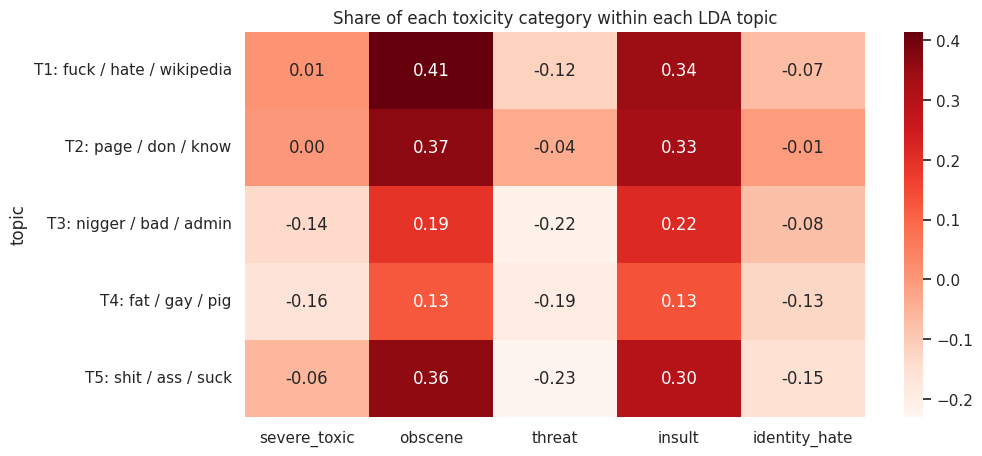

In [18]:
dom = lda.transform(Xc).argmax(1)
ct = pd.DataFrame({"topic": [topic_labels[i] for i in dom]}).join(tox_en[LABELS[1:]].reset_index(drop=True))
plt.figure(figsize=(10, 0.6 * K + 2))
sns.heatmap(ct.groupby("topic")[LABELS[1:]].mean(), annot=True, fmt=".2f", cmap="Reds")
plt.title("Share of each toxicity category within each LDA topic"); plt.show()

joblib.dump({"vectorizer": cv, "lda": lda, "topic_labels": topic_labels}, f"{ART_DIR}/topic_model.joblib")
METRICS["topics"] = [{"topic": l, "keywords": w} for l, w in zip(topic_labels, topic_words)]
METRICS["training"]["lda_topics"] = K

## 9 · Multilingual NLP with a cloud AI service  `CO3`
* **Language identification** for English / Hindi / Hinglish (script ratio + Hinglish lexical markers).
* **Google Cloud Translate** (via `deep-translator`) translates Hindi/Hinglish → English.
* **Translation-assisted ensemble:** score = max(mBERT(original), mBERT(translation)) per category. Evaluated below.

In [19]:
from deep_translator import GoogleTranslator
MARKERS = set("hai hain nahi nhi kya tum tu mera tera teri bhai yaar kar karo raha gaya aur ki ka ke ko se mein bhi sab kuch koi pagal chal dekh bol main mujhe tujhe".split())
def detect_lang(t):
    dev = len(re.findall(r"[ऀ-ॿ]", t)); lat = len(re.findall(r"[A-Za-z]", t))
    if dev / max(dev + lat, 1) >= 0.6: return "hi"
    w = [x.lower() for x in re.findall(r"[A-Za-z']+", t)]
    return "hinglish" if w and len(set(w) & MARKERS) >= 2 and sum(x in MARKERS for x in w) / len(w) >= 0.2 else "en"

samp = test_df.groupby("lang").sample(300, random_state=SEED)
samp["pred_lang"] = samp.text.map(detect_lang)
METRICS["language_id"] = {"accuracy": float(accuracy_score(samp.lang, samp.pred_lang))}
print("Language-ID accuracy:", METRICS["language_id"])
print(pd.crosstab(samp.lang, samp.pred_lang))

Language-ID accuracy: {'accuracy': 0.7522222222222222}
pred_lang   en   hi  hinglish
lang                         
en         300    0         0
hi           5  295         0
hinglish   117  101        82


In [20]:
import requests
def translate(t):
    for _ in range(3):
        try:
            r = requests.get("https://translate.googleapis.com/translate_a/single",
                             params={"client": "gtx", "sl": "auto", "tl": "en", "dt": "t", "q": t[:4500]}, timeout=10)
            return "".join(seg[0] for seg in r.json()[0] if seg and seg[0]) or t
        except Exception:
            try: return GoogleTranslator(source="auto", target="en").translate(t[:4500]) or t
            except Exception: time.sleep(1.5)
    return t

ml = test_df[test_df.lang.isin(["hi", "hinglish"])].groupby("lang").sample(120, random_state=SEED).copy()
ml["translation"] = [translate(t) for t in ml.model_text]

@torch.no_grad()
def score(texts, bs=64):
    model.eval(); out = []
    for i in range(0, len(texts), bs):
        enc = tokenizer(texts[i:i+bs], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(model.device)
        out.append(torch.sigmoid(model(**enc).logits).float().cpu().numpy())
    return np.concatenate(out)

p_orig = score(ml.model_text.tolist())[:, 0]; p_tr = score(ml.translation.tolist())[:, 0]
y = ml.toxic.values
f1_wo = f1_score(y, p_orig >= THRESH["toxic"]); f1_w = f1_score(y, np.maximum(p_orig, p_tr) >= THRESH["toxic"])
METRICS["translation_ensemble"] = {"n": len(ml), "f1_without": float(f1_wo), "f1_with": float(f1_w)}
print(METRICS["translation_ensemble"])
ml[["lang", "model_text", "translation", "toxic"]].head(8)

{'n': 240, 'f1_without': 0.8634686346863468, 'f1_with': 0.8686131386861314}


,lang,model_text,translation,toxic
52726,hi,"वडाला रेलवे स्टेशन पर समाजवादी पार्टी के नेता अबू आज़मी के सामने मुसलमानों ने लगाए ""पा...","Muslims raised slogans of ""Pakistan Zindabad"" in front of Samajwadi Party leader Abu A...",1
53410,hi,एक छोटी सी बच्ची गली में 4-5 कुत्तों को देखकर डर गई कुत्ते बोले निकल जाओ बेटी हम कुत्त...,"A little girl got scared after seeing 4-5 dogs in the street, the dogs said, get out, ...",1
54768,hi,फिल्म अभिनेत्री कंगना रनौत को गृह मंत्रालय ने दी Y श्रेणी की सुरक्षा: सूत्र,Home Ministry gives Y category security to film actress Kangana Ranaut: Sources,0
55856,hi,"‘ईज ऑफ डूइंग बिजनेस’ रैंकिंग में उत्तर प्रदेश की बड़ी छलांग, बना नंबर दो उत्तर प्रदेश ...","Big jump for Uttar Pradesh in 'Ease of Doing Business' ranking, becoming number two. T...",0
54945,hi,ChennaiSuperKings के खिलाड़ी DeepakChahar कोरोना से ठीक हो चुके हैं।,ChennaiSuperKings player DeepakChahar has recovered from Corona.,0
52116,hi,सर रेटिंग और बड़ जाए तो खाक ए रत्न के लिए प्रोमोट किया जा सकता है ओउल को 😂😂😛😛😀,"Sir, if the rating increases further then Owl can be promoted for Khaak-e-Ratna 🤔😛😛😀",1
53135,hi,15 वर्ष तक कांग्रेस के कुशासन ने भ्रष्टाचार के कई आयाम लिखें तो पिछले 53 महीने से दिल्...,The misgovernance of Congress for 15 years has written many dimensions of corruption a...,1
52098,hi,फ़ेंकू कमीना,throw it away bastard,1


## 9b · Explainability (XAI) — Integrated Gradients
Word-level attributions w.r.t. a category logit (same algorithm as `src/explainer.py`). The **completeness residual**
(Σ attributions − (f(x) − f(baseline))) should be close to 0.

In [21]:
def integrated_gradients(text, label="toxic", steps=32):
    model.eval(); li = LABELS.index(label)
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN, return_offsets_mapping=True)
    offs = enc.pop("offset_mapping")[0].tolist(); enc = {k: v.to(model.device) for k, v in enc.items()}
    ids = enc["input_ids"]; extra = {k: v for k, v in enc.items() if k != "input_ids"}
    special = torch.tensor(tokenizer.get_special_tokens_mask(ids[0].tolist(), already_has_special_tokens=True), dtype=torch.bool)
    base = ids.clone(); base[0, ~special.to(ids.device)] = tokenizer.pad_token_id
    emb = model.get_input_embeddings()
    with torch.no_grad(): x, b = emb(ids).float(), emb(base).float()
    grads = torch.zeros_like(x[0])
    for a in ((torch.arange(steps) + 0.5) / steps).to(x.device):
        e = (b + a * (x - b)).requires_grad_(True)
        logit = model(inputs_embeds=e, **extra).logits[0, li]
        grads += torch.autograd.grad(logit, e)[0][0]
    attr = ((x[0] - b[0]) * grads / steps).sum(-1).detach().cpu()
    with torch.no_grad(): delta = attr.sum() - (model(inputs_embeds=x, **extra).logits[0, li] - model(inputs_embeds=b, **extra).logits[0, li]).cpu()
    words = [(m.group(), m.start(), m.end()) for m in re.finditer(r"\S+", text)]; sc = np.zeros(len(words))
    for t, (s, e_) in enumerate(offs):
        if special[t] or e_ <= s: continue
        for wi, (_, ws, we) in enumerate(words):
            if ws <= s < we: sc[wi] += attr[t].item(); break
    return [(w, round(v, 3)) for (w, _, _), v in zip(words, sc)], float(delta)

for s in ["You are a pathetic idiot and nobody likes you", "तू एक नंबर का बेवकूफ है", "Chup kar bewakoof, teri aukaat nahi hai"]:
    attrs, d = integrated_gradients(s)
    print(f"\n{s}\n  residual={d:+.3f}  top:", sorted(attrs, key=lambda x: -x[1])[:4])


You are a pathetic idiot and nobody likes you
  residual=-0.000  top: [('idiot', np.float64(0.969)), ('pathetic', np.float64(0.281)), ('are', np.float64(0.279)), ('You', np.float64(0.186))]

तू एक नंबर का बेवकूफ है
  residual=-0.003  top: [('एक', np.float64(0.256)), ('का', np.float64(0.068)), ('बेवकूफ', np.float64(-0.07)), ('है', np.float64(-0.15))]

Chup kar bewakoof, teri aukaat nahi hai
  residual=-0.003  top: [('Chup', np.float64(0.485)), ('kar', np.float64(0.229)), ('hai', np.float64(-0.142)), ('teri', np.float64(-0.23))]


## 10 · Generative AI — prompt engineering with Claude  `CO4`
We compare three prompting strategies for toxic/non-toxic judgement on a balanced multilingual sample:

1. **Zero-shot** – role + category definitions + JSON schema.
2. **Few-shot** – adds labelled English / Hindi / Hinglish demonstrations.
3. **XAI-grounded** – few-shot + the mBERT probabilities and Integrated-Gradients words injected as evidence.

All strategies use **structured outputs** (JSON schema) so answers are machine-parseable. Requires `ANTHROPIC_API_KEY`.

In [22]:
import anthropic
CLAUDE_MODEL = "claude-opus-5-5"
SCHEMA = {"type": "object", "properties": {
    "verdict": {"type": "string", "enum": ["toxic", "non_toxic"]},
    "categories": {"type": "array", "items": {"type": "string", "enum": LABELS + ["none"]}},
    "explanation": {"type": "string"},
    "detoxified_rewrite": {"type": "string"}},
  "required": ["verdict", "categories", "explanation", "detoxified_rewrite"], "additionalProperties": False}

SYSTEM = ('You are a content-moderation analyst for English, Hindi and Hinglish comments. Categories: toxic, severe_toxic, '
          'obscene, threat, insult, identity_hate. Consider slang, sarcasm and friendly banter. Explain in 2-3 sentences and '
          'give a detoxified rewrite that keeps the meaning and language of the original.')
FEW_SHOT = ('\n\nExamples:\n"You are an absolute idiot" -> toxic [toxic, insult]\n'
            '"Tu pagal hai kya, nikal yahan se" -> toxic [toxic, insult]\n'
            '"इस फिल्म की कहानी बहुत अच्छी थी" -> non_toxic [none]\n"Main tujhe jaan se maar dunga" -> toxic [toxic, threat]')

def make_prompt(strategy, text):
    system = SYSTEM + (FEW_SHOT if strategy != "zero_shot" else "")
    user = f"<comment>\n{text}\n</comment>"
    if strategy == "xai_grounded":
        p = score([clean_for_model(text)])[0]; words, _ = integrated_gradients(clean_for_model(text))
        user += ("\n<classifier_evidence>\n" + "\n".join(f"{l}: {v:.1%}" for l, v in zip(LABELS, p)) +
                 "\nTop words: " + ", ".join(f"{w} ({s:+.2f})" for w, s in sorted(words, key=lambda x: -x[1])[:5]) + "\n</classifier_evidence>")
    return system, user + "\nReturn the JSON object."

def ask_claude(strategy, text):
    system, user = make_prompt(strategy, text)
    r = client.messages.create(model=CLAUDE_MODEL, max_tokens=2000, system=system,
                               messages=[{"role": "user", "content": user}],
                               output_config={"effort": "low", "format": {"type": "json_schema", "schema": SCHEMA}})
    if r.stop_reason == "refusal": return {"verdict": "toxic", "categories": [], "explanation": "refused", "detoxified_rewrite": ""}
    return json.loads(next(b.text for b in r.content if b.type == "text"))

if ANTHROPIC_API_KEY:
    client = anthropic.Anthropic(api_key=ANTHROPIC_API_KEY)
    llm_s = test_df.groupby(["lang", "toxic"]).sample(5, random_state=SEED)   # 30 comments, balanced
    res = {}
    for strat in ["zero_shot", "few_shot", "xai_grounded"]:
        preds = [int(ask_claude(strat, t)["verdict"] == "toxic") for t in llm_s.text]
        res[strat] = {"accuracy": accuracy_score(llm_s.toxic, preds), "f1": f1_score(llm_s.toxic, preds), "n": len(preds)}
        print(strat, res[strat])
    METRICS["llm_eval"] = res
else:
    print("ANTHROPIC_API_KEY not set - skipping LLM evaluation.")

ANTHROPIC_API_KEY not set - skipping LLM evaluation.


In [23]:
# Generative explanation + counterfactual check: re-score Claude's detoxified rewrite with mBERT
if ANTHROPIC_API_KEY:
    for t in ["Tu ek number ka chutiya hai, nikal yahan se", "You are a disgusting moron and I hope you die"]:
        out = ask_claude("xai_grounded", t)
        before, after = score([clean_for_model(t)])[0, 0], score([out["detoxified_rewrite"]])[0, 0]
        print(f"\nCOMMENT : {t}\nVERDICT : {out['verdict']} {out['categories']}\nWHY     : {out['explanation']}"
              f"\nREWRITE : {out['detoxified_rewrite']}\nP(toxic): {before:.2f} -> {after:.2f}")

## 11 · Export model & artifacts for the Streamlit app

In [26]:
trainer.save_model(OUT_DIR); tokenizer.save_pretrained(OUT_DIR)
json.dump(THRESH, open(f"{OUT_DIR}/thresholds.json", "w"), indent=2)
json.dump(THRESH, open(f"{ART_DIR}/thresholds.json", "w"), indent=2)
METRICS["model_repo"] = HF_REPO
json.dump(METRICS, open(f"{ART_DIR}/metrics.json", "w"), indent=2, ensure_ascii=False)

if HF_TOKEN and "YOUR_HF_USERNAME" not in HF_REPO:
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    api.create_repo(HF_REPO, exist_ok=True, private=False)
    api.upload_folder(folder_path=OUT_DIR, repo_id=HF_REPO, commit_message="ToxicGuardAI fine-tuned mBERT")
    print(f"✅ Model pushed: https://huggingface.co/{HF_REPO}")
else:
    print("⚠️ Set HF_REPO and the HF_TOKEN secret to push the model.")

!zip -qr artifacts.zip artifacts
try:
    from google.colab import files; files.download("artifacts.zip")
except Exception: pass
print(os.listdir(ART_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model pushed: https://huggingface.co/Vivek1717/toxicguard-mbert


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

['tfidf.joblib', 'metrics.json', 'topic_model.joblib', 'thresholds.json']


In [ ]:
# Quick sanity check of the saved model (what the app will load)
from transformers import pipeline
pipe = pipeline("text-classification", model=OUT_DIR, top_k=None, function_to_apply="sigmoid", device=0 if DEVICE == "cuda" else -1)
for s in ["Have a great day!", "You are a stupid idiot", "तुझे जान से मार दूंगा", "Bhai mast video hai"]:
    print(s, "->", {d["label"]: round(d["score"], 3) for d in pipe(s)[0]})

In [29]:
import json
M = json.load(open(f"{ART_DIR}/metrics.json"))
for k, v in METRICS.items():
    M.setdefault(k, v)

# true labels / predictions (recomputed in case any variable is missing)
yt_b = test_y[:, 0].astype(int)
pr_b = (test_p[:, 0] >= THRESH["toxic"]).astype(int)
_bp  = (base_probs[:, 0] >= 0.5).astype(int)

# TF-IDF + Logistic Regression baseline
bl = {}
for j, lab in enumerate(LABELS):
    m = test_y[:, j] >= 0; yt = test_y[m, j].astype(int)
    bl[lab] = {"f1": float(f1_score(yt, base_probs[m, j] >= 0.5)), "roc_auc": float(roc_auc_score(yt, base_probs[m, j]))}
M["baseline_tfidf"] = {"per_label": bl,
    "macro_f1": float(np.mean([v["f1"] for v in bl.values()])), "macro_auc": float(np.mean([v["roc_auc"] for v in bl.values()])),
    "accuracy": float(accuracy_score(yt_b, _bp)), "precision": float(precision_score(yt_b, _bp)),
    "recall": float(recall_score(yt_b, _bp)), "f1_toxic": float(f1_score(yt_b, _bp))}

M.setdefault("overall", {}).update({"binary_precision": float(precision_score(yt_b, pr_b)),
                                    "binary_recall": float(recall_score(yt_b, pr_b))})
M["dataset"] = {"total": len(df), "train": len(train_df), "val": len(val_df), "test": len(test_df),
                "by_source_lang": df.groupby(["source", "lang"]).agg(n=("text", "size"), toxic_rate=("toxic", "mean")).reset_index().to_dict("records")}
M.setdefault("training", {})["gpu"] = torch.cuda.get_device_name(0)

json.dump(M, open(f"{ART_DIR}/metrics.json", "w"), indent=2, ensure_ascii=False, default=float)
print("Saved. Sections in metrics.json:", list(M.keys()))
print("mBERT  :", {k: round(M["overall"][k], 3) for k in M["overall"]})
print("TF-IDF :", {k: round(v, 3) for k, v in M["baseline_tfidf"].items() if k != "per_label"})

!rm -f artifacts.zip && zip -qr artifacts.zip artifacts
from google.colab import files; files.download("artifacts.zip")

Saved. Sections in metrics.json: ['training', 'model_repo', 'baseline_tfidf', 'overall', 'dataset']
mBERT  : {'binary_precision': 0.855, 'binary_recall': 0.903}
TF-IDF : {'macro_f1': 0.64, 'macro_auc': 0.956, 'accuracy': 0.898, 'precision': 0.864, 'recall': 0.858, 'f1_toxic': 0.861}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
import json
M = json.load(open(f"{ART_DIR}/metrics.json"))

def safe(name, fn):
    try:
        fn(); print("✅", name)
    except Exception as e:
        print("⚠️ skipped", name, "->", type(e)._name_, e)

def _overall():
    yt_b = test_y[:, 0].astype(int); pr_b = (test_p[:, 0] >= THRESH["toxic"]).astype(int)
    pl, all_t, all_p = {}, [], []
    for j, lab in enumerate(LABELS):
        m = test_y[:, j] >= 0; yt, pp = test_y[m, j].astype(int), test_p[m, j]; pr = (pp >= THRESH[lab]).astype(int)
        pl[lab] = {"precision": float(precision_score(yt, pr, zero_division=0)), "recall": float(recall_score(yt, pr, zero_division=0)),
                   "f1": float(f1_score(yt, pr, zero_division=0)), "roc_auc": float(roc_auc_score(yt, pp)),
                   "support": int(yt.sum()), "threshold": float(THRESH[lab])}
        all_t.append(yt); all_p.append(pr)
    M["per_label"] = pl
    M.setdefault("overall", {}).update({
        "macro_f1": float(np.mean([v["f1"] for v in pl.values()])),
        "micro_f1": float(f1_score(np.concatenate(all_t), np.concatenate(all_p))),
        "macro_auc": float(np.mean([v["roc_auc"] for v in pl.values()])),
        "binary_accuracy": float(accuracy_score(yt_b, pr_b)), "binary_f1": float(f1_score(yt_b, pr_b)),
        "binary_precision": float(precision_score(yt_b, pr_b)), "binary_recall": float(recall_score(yt_b, pr_b))})
    M["confusion_matrix"] = confusion_matrix(yt_b, pr_b).tolist()
    M["per_language"] = {}
    for lang in ["en", "hi", "hinglish"]:
        m = (test_df.lang == lang).values
        M["per_language"][lang] = {"n": int(m.sum()), "accuracy": float(accuracy_score(yt_b[m], pr_b[m])),
                                   "f1": float(f1_score(yt_b[m], pr_b[m])), "roc_auc": float(roc_auc_score(yt_b[m], test_p[m, 0]))}

def _history():
    h, losses = [], {}
    for r in trainer.state.log_history:
        if "loss" in r: losses.setdefault(round(r["epoch"]), []).append(r["loss"])
        if "eval_macro_f1" in r:
            h.append({"epoch": round(r["epoch"]), "val_macro_f1": r["eval_macro_f1"], "val_macro_auc": r["eval_macro_auc"], "val_loss": r["eval_loss"]})
    for x in h: x["train_loss"] = float(np.mean(losses.get(x["epoch"], losses.get(x["epoch"] - 1, [np.nan]))))
    M["history"] = h

def _sentiment():
    M["sentiment_eval"] = {"dataset": "TweetEval-sentiment (n=3000)", "accuracy": float(accuracy_score(tw.label, tw.pred)),
                           "macro_f1": float(f1_score(tw.label, tw.pred, average="macro"))}

def _ie():
    tp = fp = fn = ok = 0
    for text, g_gold, t_gold in GOLD:
        g, t = extract(text); tp += len(g & g_gold); fp += len(g - g_gold); fn += len(g_gold - g); ok += t == t_gold
    P, R = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    M["ie_eval"] = {"precision": P, "recall": R, "f1": 2 * P * R / max(P + R, 1e-9), "target_accuracy": ok / len(GOLD), "n": len(GOLD)}

def _langid():
    M["language_id"] = {"accuracy": float(accuracy_score(samp.lang, samp.pred_lang))}

def _translation():
    y = ml.toxic.values
    M["translation_ensemble"] = {"n": len(ml), "f1_without": float(f1_score(y, p_orig >= THRESH["toxic"])),
                                 "f1_with": float(f1_score(y, np.maximum(p_orig, p_tr) >= THRESH["toxic"]))}

def _topics():
    M["topics"] = [{"topic": l, "keywords": list(w)} for l, w in zip(topic_labels, topic_words)]
    M.setdefault("training", {})["lda_topics"] = int(K)

def _training():
    M.setdefault("training", {}).update({"base_model": MODEL_NAME, "max_len": MAX_LEN, "epochs": EPOCHS, "batch_size": BATCH,
        "learning_rate": LR, "loss": "masked BCE with pos_weight", "seed": SEED,
        "train_rows": len(train_bal), "val_rows": len(val_df), "test_rows": len(test_df),
        "train_runtime_min": round(train_out.metrics["train_runtime"] / 60, 1)})

for name, fn in [("overall + per-label + per-language + confusion matrix", _overall), ("training history", _history),
                 ("sentiment", _sentiment), ("information extraction", _ie), ("language ID", _langid),
                 ("translation ensemble", _translation), ("topics", _topics), ("training config", _training)]:
    safe(name, fn)
if "llm_eval" in globals() or "res" in globals():
    safe("LLM eval", lambda: M._setitem_("llm_eval", {k: {kk: float(vv) for kk, vv in v.items()} for k, v in res.items()}))

json.dump(THRESH, open(f"{ART_DIR}/thresholds.json", "w"), indent=2)
json.dump(M, open(f"{ART_DIR}/metrics.json", "w"), indent=2, ensure_ascii=False, default=float)
print("\nSections:", list(M.keys()))
print("Overall:", {k: round(v, 3) for k, v in M["overall"].items()})
print("Per language:", {k: (round(v["f1"], 3), round(v["roc_auc"], 3)) for k, v in M["per_language"].items()})
print("Thresholds:", {k: round(v, 2) for k, v in THRESH.items()})
!rm -f artifacts.zip && zip -qr artifacts.zip artifacts
from google.colab import files; files.download("artifacts.zip")

✅ overall + per-label + per-language + confusion matrix
✅ training history
✅ sentiment
✅ information extraction
✅ language ID
✅ translation ensemble
✅ topics
✅ training config

Sections: ['training', 'model_repo', 'baseline_tfidf', 'overall', 'dataset', 'per_label', 'confusion_matrix', 'per_language', 'history', 'sentiment_eval', 'ie_eval', 'language_id', 'translation_ensemble', 'topics']
Overall: {'binary_precision': 0.855, 'binary_recall': 0.903, 'macro_f1': 0.693, 'micro_f1': 0.826, 'macro_auc': 0.965, 'binary_accuracy': 0.908, 'binary_f1': 0.879}
Per language: {'en': (0.886, 0.977), 'hi': (0.94, 0.988), 'hinglish': (0.757, 0.803)}
Thresholds: {'toxic': 0.6, 'severe_toxic': 0.84, 'obscene': 0.81, 'threat': 0.61, 'insult': 0.8, 'identity_hate': 0.91}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### ✅ Next steps
1. Unzip `artifacts.zip` into the repo's `artifacts/` folder (`metrics.json`, `thresholds.json`, `tfidf.joblib`, `topic_model.joblib`).
2. Set `MODEL_ID = "<your-username>/toxicguard-mbert"` in `.streamlit/secrets.toml` (and in Streamlit Cloud → *Secrets*).
3. `git add artifacts && git commit -m "Add trained artifacts" && git push` → Streamlit Cloud redeploys automatically.